In [ ]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
pip install --upgrade pi

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


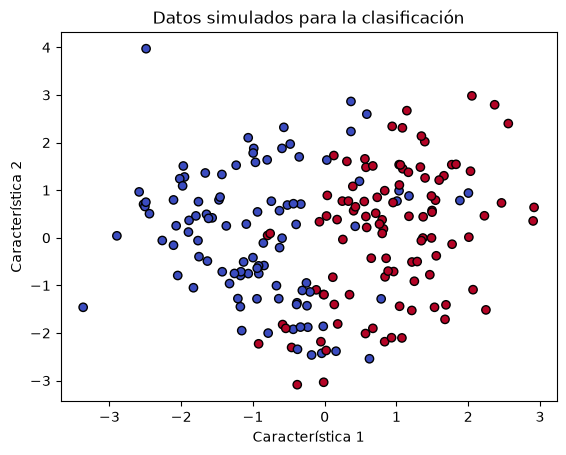

In [24]:
from sklearn.datasets import make_classification
import matplotlib.pyplot as plt

x, y = make_classification(
    n_samples=200,
    n_features=2,
    n_redundant=0,
    random_state=42,
)

plt.scatter(x[:, 0], x[:, 1], c=y, cmap="coolwarm", edgecolors="k")
plt.title("Datos simulados para la clasificación")
plt.xlabel("Característica 1")
plt.ylabel("Característica 2")
plt.show()

In [28]:
pip install mlxtend

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


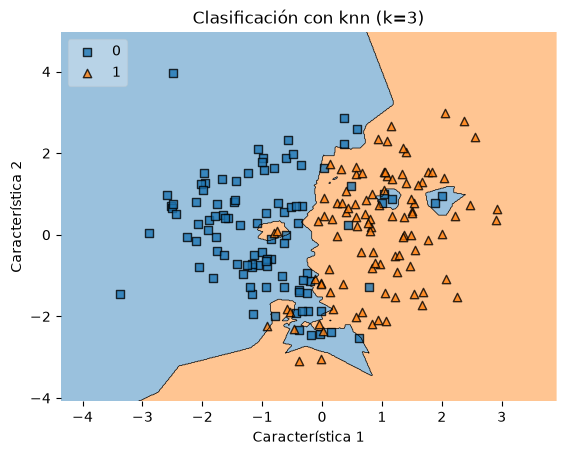

In [34]:
from sklearn.neighbors import KNeighborsClassifier
from mlxtend.plotting import plot_decision_regions

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(x, y)

plot_decision_regions(x,y, clf=knn, legend=2)
plt.title("Clasificación con knn (k=3)")
plt.xlabel("Característica 1")
plt.ylabel("Característica 2")
plt.show()

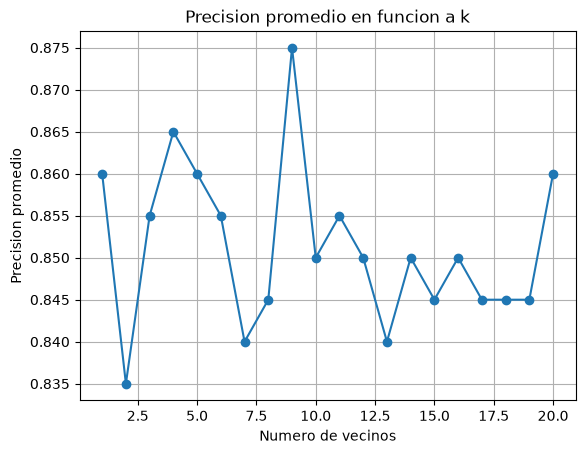

In [37]:
from sklearn.model_selection import cross_val_score
import numpy as np

k_values = list(range(1,21))
accuracies = []

for k in k_values:
    knn=KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn,x,y,cv=5, scoring="accuracy")
    accuracies.append(scores.mean())

plt.plot(k_values, accuracies, marker="o")
plt.title("Precision promedio en funcion a k")
plt.xlabel("Numero de vecinos")
plt.ylabel("Precision promedio")
plt.grid()
plt.show()

El mejor valor de k es: 9


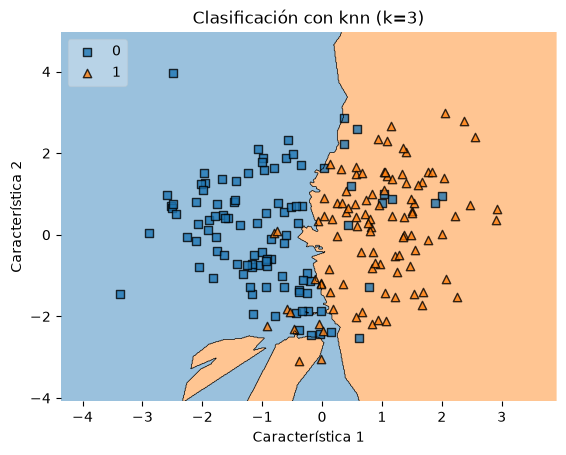

In [40]:
best_k = k_values[np.argmax(accuracies)]
print(f"El mejor valor de k es: {best_k}")

knn_best = KNeighborsClassifier(n_neighbors=best_k)
knn_best.fit(x,y)

plot_decision_regions(x,y, clf=knn_best, legend=2)
plt.title("Clasificación con knn (k=3)")
plt.xlabel("Característica 1")
plt.ylabel("Característica 2")
plt.show()

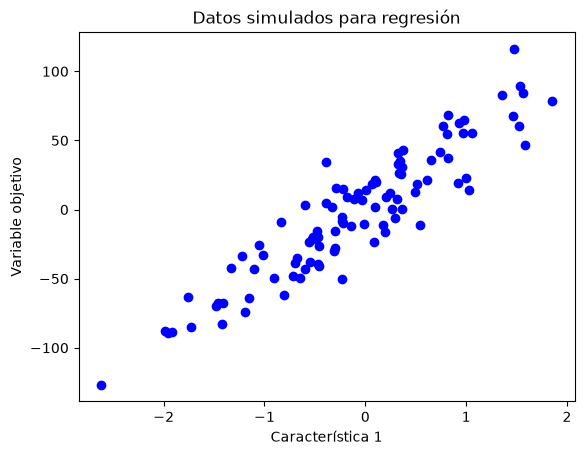

In [46]:
#Ejercicio2
from sklearn.datasets import make_regression

x, y = make_regression(
    n_samples=100,
    n_features=1,
    noise=20,
    random_state=42
    )

plt.scatter(x, y, color="blue")
plt.title("Datos simulados para regresión")
plt.xlabel("Característica 1")
plt.ylabel("Variable objetivo")
plt.show()

MSE: 14.257076
R2: 0.853029


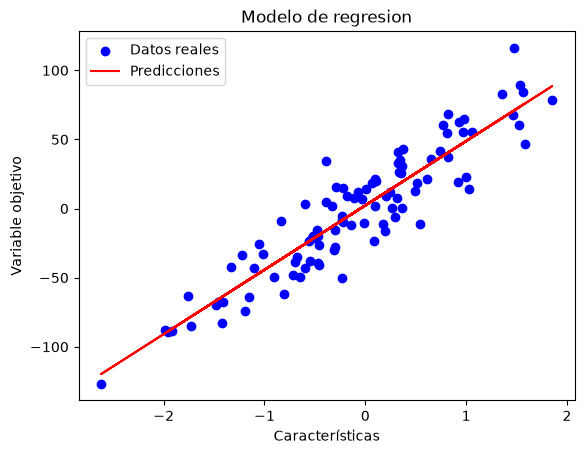

In [49]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score

ridge = Ridge(alpha=1.0)
ridge.fit(x, y)

y_pred = ridge.predict(x)
mse = mean_absolute_error(y, y_pred)
r2 = r2_score(y, y_pred)

print(f"MSE: {mse:2f}")
print(f"R2: {r2:2f}")

plt.scatter(x, y, color="blue", label = "Datos reales")
plt.plot(x, y_pred, color="red", label = "Predicciones")
plt.title("Modelo de regresion")
plt.xlabel("Características")
plt.ylabel("Variable objetivo")
plt.legend()
plt.show()

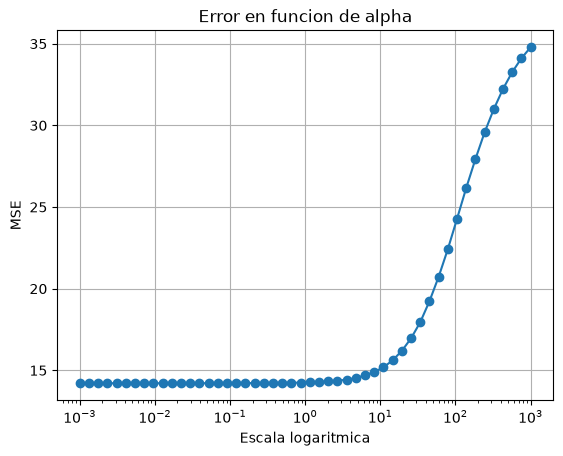

In [51]:
alphas = np.logspace(-3, 3, 50)
errors = []

for alpha in alphas:
    ridge = Ridge(alpha=alpha)
    ridge.fit(x, y)
    y_pred=ridge.predict(x)
    errors.append(mean_absolute_error(y, y_pred))

plt.plot(alphas, errors, marker="o")
plt.xscale("log")
plt.title("Error en funcion de alpha")
plt.xlabel("Escala logaritmica")
plt.ylabel("MSE")
plt.grid()
plt.show()

Mejor valor de alpha: 0.001


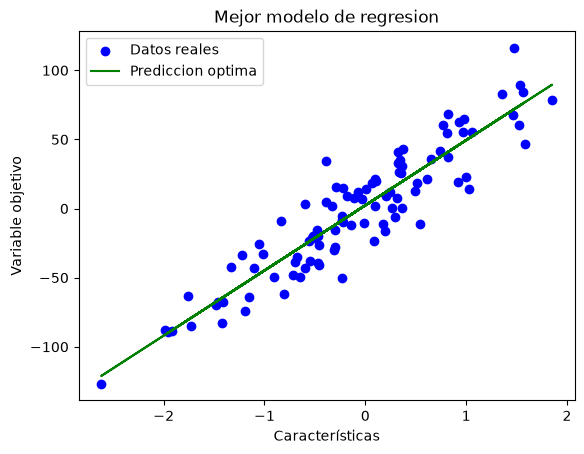

In [52]:
best_alpha = alphas[np.argmin(errors)]
print(f"Mejor valor de alpha: {best_alpha}")

ridge_best = Ridge(alpha=best_alpha)
ridge_best.fit(x, y)
y_pred_best = ridge_best.predict(x)

plt.scatter(x, y, color="blue", label = "Datos reales")
plt.plot(x, y_pred_best, color="green", label = "Prediccion optima")
plt.title("Mejor modelo de regresion")
plt.xlabel("Características")
plt.ylabel("Variable objetivo")
plt.legend()
plt.show()